# coevolution-substrate (#3 / #3c) *(draft digest)*

> **Status:** DRAFT in `Research/_drafts/` — approval-gated (see `Research/README.md`).

## Question

**Does egene co-evolution amplify rule selection — and is there a real penalty for *freezing*
the substrate rule?** (#3 asked whether egene evolution depends on the substrate; #3c is the
clean decisive test.)

## Model

Standard model (capped mouthful, `food_cap=1`). Data: the 2026-10-23 standard-model rescans
`Scans/2026-10-23_3c_coevolution_substrate_standard` and `Scans/2026-10-23_pure_evo_egene_on_winners_standard`
(same configs and protocol as the May scans, today's code). The May scans ran the legacy uncapped rule
(`food_cap=0`), which is not part of the model; every row has `m_scale` 1.5-3, where the cap can bind.

## Method

`3c_coevolution_substrate` (`Research/Lineage-co-evolution/plans/plan-3c-coevolution-substrate.md`): evolve LUT-only for a
phase-1 settle (3000 ticks), then **in situ** switch to egene evolution for phase 2 (8000
ticks). Regime `m_scale=3.0, food_inc=0.015, tax=0.035, gdiff=0.06`, N=256. Four arms, 80 runs,
determinism-checked (30/30 A/C pairs `determinism_ok=True`, shared fork valid):

- **A** — freeze the *evolved* LUT (`mu_lut=0`), evolve egene;
- **C** — keep the LUT **co-evolving**, evolve egene (byte-identical substrate to A at switch);
- **B** — freeze **GoL** after the 3000-tick settle — anchor;
- **B′** — freeze GoL after a 100-tick settle — anchor.

Substrate premise holds: A/C `frac_evolved = 1.000`, ~36k distinct LUTs at the switch.

## Headline result (standard model)

**Freezing the rule at GoL costs nothing, and the only coupling signal left is a small C-over-A advantage.**
In #3, 3a (LUT evolving) and 3b (LUT frozen at GoL) are equal: extinction 3/144 vs 2/144, mean
`eg_excess_pc_slope` 22.6 vs 24.0, 3a ahead on 5 of 12 base regimes. In #3c no arm goes extinct
(B 0/10), and the GoL anchors carry late-window egene excess (B +0.97, B′ +2.44) as large as the
evolved-substrate arms (C +1.35, A −0.06). From a byte-identical substrate, co-evolving the rule (**C**)
beats freezing it (**A**) modestly and consistently: paired C−A `eg_excess_pc_slope > 0` in 27/30, mean +0.44.
Whole-phase-2 slopes are negative in A and C because the excess carried over the switch decays
(early-window slope −27; the shadow is not re-baselined, follow-up F1), so the late window is the cleaner read.
The `dyn_excess_pc` frozen-rich-substrate artifact does **not** appear (0/30 A runs with slope > 50).

**Superseded (legacy rule):** the recorded headline ("3a ≫ 3b; #3 gap mostly a GoL-substrate death confound,
B 10/10 extinct; C>A 22/30, mean +0.6; A `dyn_excess_pc_slope` ≈ +335 artifact") was a legacy-rule result.
A legacy rerun with today's code reproduces those extinctions and the artifact; see the "Legacy rule" section
of `Lineage-co-evolution.ipynb`.

In [1]:
# --- draft digest notebook: shared setup ---
# Locates the repo root (dir containing C/evoca.h) by walking up from CWD,
# so the notebook loads raw artifacts wherever it is executed from.
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

def repo_root():
    p = Path.cwd().resolve()
    for cand in [p, *p.parents]:
        if (cand / "C" / "evoca.h").is_file():
            return cand
    raise FileNotFoundError("could not locate repo root (no C/evoca.h above CWD)")

ROOT = repo_root()
print("repo root:", ROOT)


repo root: /private/tmp/evoca_food-cap-standard


In [2]:
c3 = pd.read_csv(ROOT / "Research/Lineage-co-evolution/Scans/2026-10-23_3c_coevolution_substrate_standard/results.csv")
byarm = c3.groupby("arm").agg(
    n=("arm", "size"),
    extinct=("extinct", "sum"),
    eg_excess_pc_slope=("eg_excess_pc_slope", "mean"),
    eg_excess_pc_slope_late=("eg_excess_pc_slope_late", "mean"),
    dyn_excess_pc_slope=("dyn_excess_pc_slope", "mean"),
    frac_evolved=("sub_frac_evolved", "mean"),
    n_lut_at_switch=("sub_n_lut", "mean"),
).round(3).reindex(["A", "C", "B", "B'"])
display(byarm)
d3 = pd.read_csv(ROOT / "Research/Lineage-co-evolution/Scans/2026-10-23_pure_evo_egene_on_winners_standard/results.csv")
display(d3.groupby("mode").agg(n=("mode", "size"), extinct=("extinct", "sum"),
                               eg_excess_pc_slope_mean=("eg_excess_pc_slope", "mean"),
                               eg_excess_pc_slope_median=("eg_excess_pc_slope", "median")).round(2))

,n,extinct,eg_excess_pc_slope,eg_excess_pc_slope_late,dyn_excess_pc_slope,frac_evolved,n_lut_at_switch
arm,,,,,,,
A,30,0,-1.628,-0.065,-1.334,1.0,35912.167
C,30,0,-1.186,1.349,3.559,1.0,35912.167
B,10,0,0.693,0.972,0.000,0.0,1.000
B',10,0,1.442,2.439,0.000,0.0,1.000


,n,extinct,eg_excess_pc_slope_mean,eg_excess_pc_slope_median
mode,,,,
3a,144,3,22.61,10.62
3b,144,2,23.96,15.35


### Viability by arm, and the paired C vs A comparison

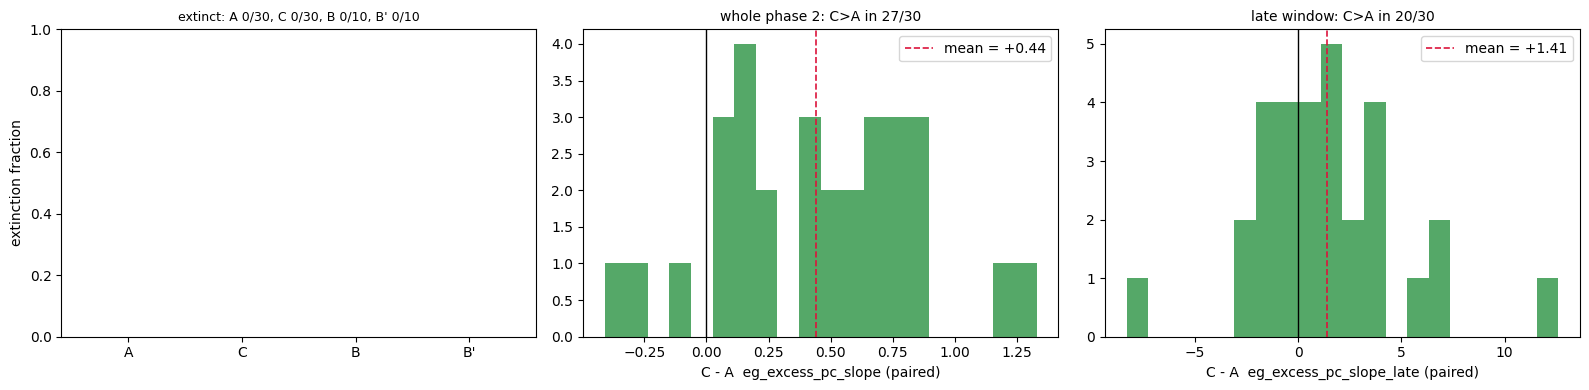

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# (a) extinction by arm
order = ["A", "C", "B", "B'"]
ext = [c3.query("arm==@a").extinct.mean() for a in order]
axes[0].bar(order, ext, color=["#4C72B0", "#55A868", "#C44E52", "#8172B3"])
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("extinction fraction")
axes[0].set_title(f"extinct: " + ", ".join(f"{a} {int(c3.query('arm==@a').extinct.sum())}/{(c3.arm == a).sum()}" for a in order), fontsize=9)

# (b), (c) paired C - A eg excess slope (matched seed / phase-1 mu_lut), whole phase 2 and late window
key = ["seed", "param_mu_lut_p1"]
for ax, col, lab in ((axes[1], "eg_excess_pc_slope", "whole phase 2"), (axes[2], "eg_excess_pc_slope_late", "late window")):
    a = c3.query("arm=='A'").set_index(key)[col]
    cc = c3.query("arm=='C'").set_index(key)[col]
    paired = (cc - a).dropna()
    ax.hist(paired, bins=20, color="#55A868")
    ax.axvline(0, color="k", lw=1)
    ax.axvline(paired.mean(), color="crimson", lw=1.2, ls="--", label=f"mean = {paired.mean():+.2f}")
    ax.set_xlabel(f"C - A  {col} (paired)")
    ax.set_title(f"{lab}: C>A in {int((paired>0).sum())}/{len(paired)}", fontsize=10)
    ax.legend()
fig.tight_layout(); plt.show()

### `dyn_excess_pc` on the frozen evolved substrate

Under the legacy rule arm A (`mu_lut=0` on the *evolved* substrate) showed a huge `dyn_excess_pc_slope`
(the frozen-rich-substrate baseline collapse, Bug 2 in the `neutral-model-methodology` draft). Under the standard
rule it does not: A's slopes are small and comparable to C's. Keep the precaution of reading `dyn_excess_pc` only
where `mu_lut > 0` until the artifact has been checked in a regime that saturates under the standard rule.

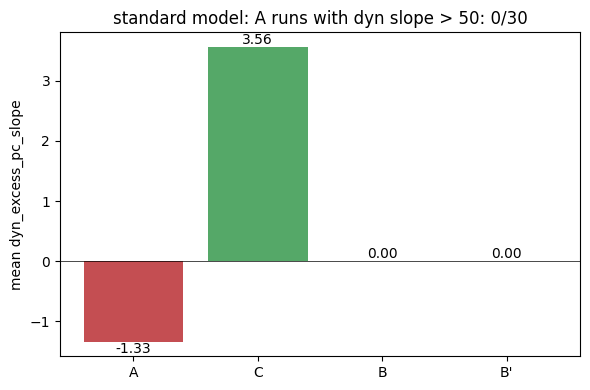

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
order = ["A", "C", "B", "B'"]
vals = [c3.query("arm==@a").dyn_excess_pc_slope.mean() for a in order]
bars = ax.bar(order, vals, color=["#C44E52", "#55A868", "#999999", "#999999"])
ax.axhline(0, color="k", lw=0.5)
ax.set_ylabel("mean dyn_excess_pc_slope")
nA = int((c3.query("arm=='A'").dyn_excess_pc_slope > 50).sum())
ax.set_title(f"standard model: A runs with dyn slope > 50: {nA}/30")
ax.bar_label(bars, fmt="%.2f")
fig.tight_layout(); plt.show()

*Sources:* `Research/Lineage-co-evolution/Scans/2026-10-23_3c_coevolution_substrate_standard/`,
`Research/Lineage-co-evolution/Scans/2026-10-23_pure_evo_egene_on_winners_standard/` (standard-model rescans);
legacy comparison: `Research/Lineage-co-evolution/Scans/2026-10-23_legacy_now_subset/` and the recorded May scans;
`Research/Lineage-co-evolution/plans/plan-3c-coevolution-substrate.md`, `Docs/devlog/2026-05-17_research-campaigns.md` (#3c section, legacy rule).